# Zomato Exploratory Data Analysis Project

# 1. Import Python Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2.Loading the Dataset

In [4]:
df=pd.read_csv("Restaurantdata.csv")
df.head()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [5]:
df.shape

(148, 7)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Restaurant Name              148 non-null    str  
 1   Online_Order                 148 non-null    str  
 2   Book_Table                   148 non-null    str  
 3   Rate                         148 non-null    str  
 4   Votes                        148 non-null    int64
 5   Approx_Cost(For Two People)  148 non-null    int64
 6   Listed_In(Type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 13.4 KB


In [8]:
df.describe(include='all')

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
count,148,148,148,148,148.000000,148.000000,148
unique,148,2,2,15,NaN,NaN,9
top,Jalsa,Yes,No,4.0/5,NaN,NaN,other
freq,1,96,113,21,NaN,NaN,22
mean,NaN,NaN,NaN,NaN,1642.425676,605.405405,NaN
std,NaN,NaN,NaN,NaN,913.249197,276.772896,NaN
min,NaN,NaN,NaN,NaN,6.000000,200.000000,NaN
25%,NaN,NaN,NaN,NaN,912.500000,387.500000,NaN
50%,NaN,NaN,NaN,NaN,1698.500000,600.000000,NaN
75%,NaN,NaN,NaN,NaN,2347.500000,800.000000,NaN


## Step-3 Data Cleaning & Preparation

# 1. Convert the Rate Column to Numeric Data Type

In [13]:
def handleRate(value):
    value = str(value).split("/")
    value = value[0]
    return float(value)
df["Rate"] = df["Rate"].apply(handleRate)
print(df.head(5))

         Restaurant Name Online_Order Book_Table  Rate  Votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   Approx_Cost(For Two People) Listed_In(Type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


# 2. Standardize Column Names

In [14]:
df.columns = df.columns.str.lower()

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant name              148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 12.7 KB


In [16]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='str')

# 3. Rename the Cost Column

In [19]:
df.rename(
    columns = { 'approx_cost(for two people)' : 'approx_cost'},
    inplace = True
    )

In [20]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost', 'listed_in(type)'],
      dtype='str')

# 4. Checking the Missing Values & Duplicate Records

In [22]:
print("Missing Values")
print(df.isnull().sum())
print("Duplicated Values:",df.duplicated().sum())

Missing Values
restaurant name    0
online_order       0
book_table         0
rate               0
votes              0
approx_cost        0
listed_in(type)    0
dtype: int64
Duplicated Values: 0


## 5. Exploratory Data Analysis
1. How many customer votes has each restuarant type received?
2. How many restuarants offer table booking?
3. Which five restuarants have the highest number of votes?
4. Is there a relationship between restuarant ratings and customer votes?
5. What is the average rating for each restuarant type?
6. What type of restuarant do the majority of customers order from?
7. What ratings do rastuarants most commonly receive?
8. Which restuarant type has the highest average cost for two people?
9. Which order mode-online or offline-gets better ratings?
10. Which restuaranr types have more offline ordering records?

## 1. How many customer votes has each restuarant type received

In [24]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [25]:
grouped_data=df.groupby("listed_in(type)")["votes"].sum()
grouped_data

listed_in(type)
Buffet           29270
Cafes            28866
Delivery         28533
Desserts         19898
Dining           27837
North Indian     30321
Pubs and bars    13388
South Indian     26178
other            38788
Name: votes, dtype: int64

# 2. How many restuarants offer table booking?


In [26]:
result=df["book_table"].value_counts()
result

book_table
No     113
Yes     35
Name: count, dtype: int64

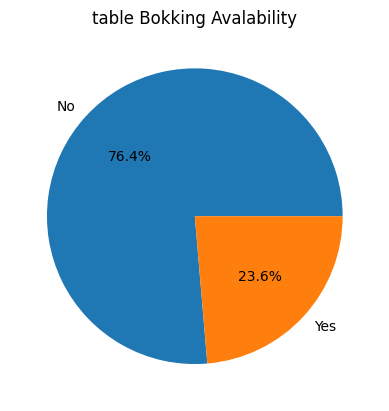

In [29]:
result.plot.pie(autopct="%1.1f%%")
plt.title("table Bokking Avalability")
plt.show()

# 3. Which five restuarants have the highest number of votes?


In [33]:
top5=df.nlargest(5,"votes")
print(top5[["restaurant name","votes"]])

            restaurant name  votes
70       Flavour Cafe Diner   3159
114  Coastal Kitchen Lounge   3120
72        Garden Hot Corner   3098
100     Royal Royal Express   3088
45       Green Cafe Kitchen   3084


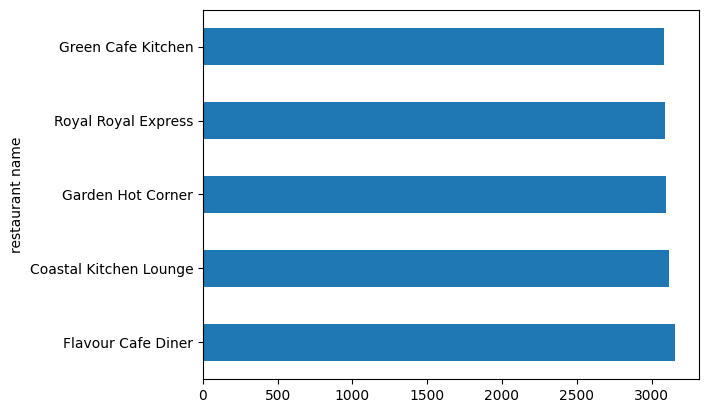

In [35]:
top5.plot.barh(x="restaurant name",y="votes",legend=False)
plt.show()

# 4. Is there a relationship between restuarant ratings and customer votes?


In [36]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


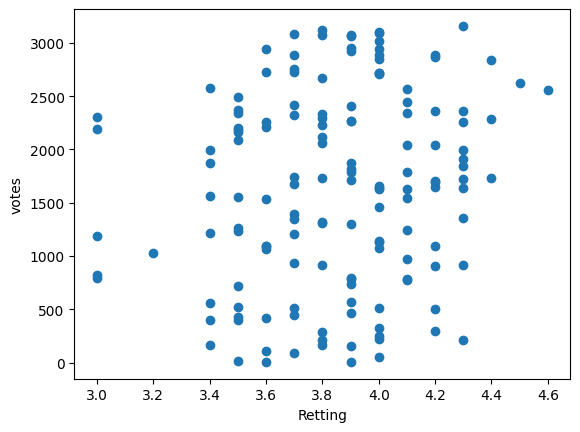

In [51]:
plt.scatter(df["rate"],df["votes"])
plt.xlabel("Retting")
plt.ylabel("votes")
plt.show()

# 5. What is the average rating for each restuarant type?


In [39]:
result=df.groupby("listed_in(type)")["rate"].mean()
result.sort_values(ascending=False)

listed_in(type)
Cafes            3.981250
North Indian     3.976471
other            3.886364
Buffet           3.873684
Dining           3.800000
Delivery         3.781250
South Indian     3.775000
Pubs and bars    3.760000
Desserts         3.700000
Name: rate, dtype: float64

# 6. What type of restuarant do the majority of customers order from?


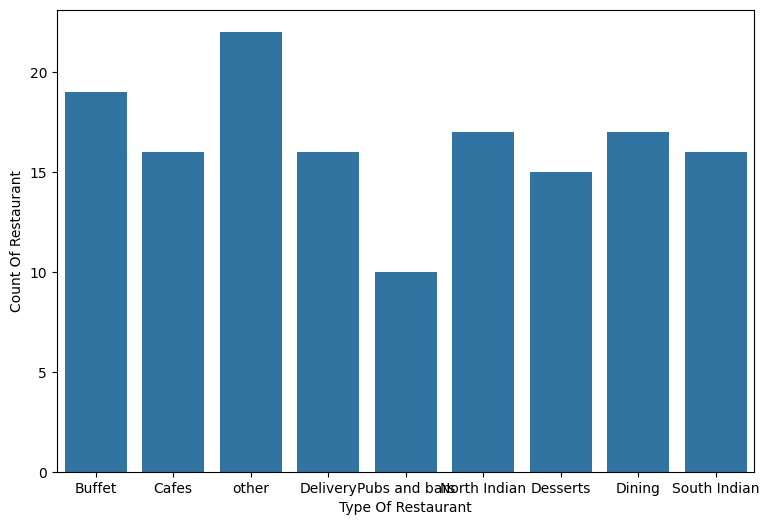

In [52]:
plt.figure(figsize=(9,6))
sns.countplot(x=df["listed_in(type)"])
plt.xlabel("Type Of Restaurant")
plt.ylabel("Count Of Restaurant")
plt.show()

# 7. What ratings do rastuarants most commonly receive?


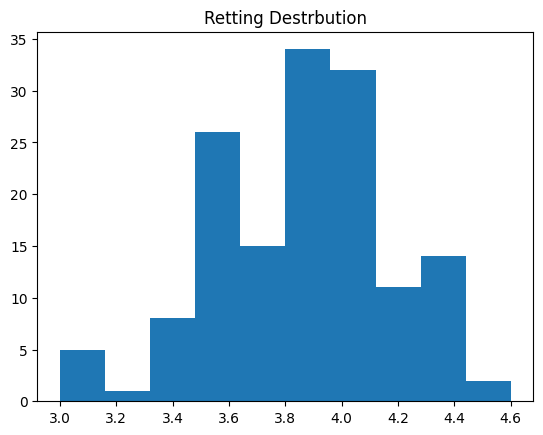

In [44]:
plt.hist(df["rate"],bins=10)
plt.title("Retting Destrbution")
plt.show()

# 8. Which restuarant type has the highest average cost for two people?


In [45]:
result=df.groupby("listed_in(type)")["approx_cost"].mean()
result.sort_values(ascending=False)

listed_in(type)
Cafes            718.750000
Pubs and bars    710.000000
Delivery         643.750000
Desserts         620.000000
other            577.272727
Dining           570.588235
South Indian     568.750000
Buffet           555.263158
North Indian     550.000000
Name: approx_cost, dtype: float64

# 9. Which order mode-online or offline-gets better ratings?


In [46]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


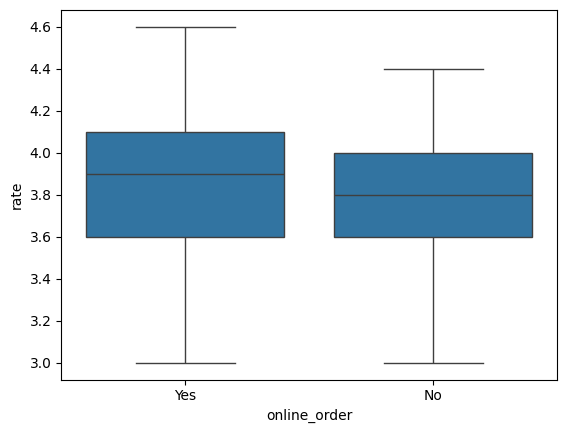

In [47]:
sns.boxplot(x="online_order",y="rate",data=df)
plt.show()

 # 10. Which restaurant types have more offline ordering records?

In [48]:
pivot_table=df.pivot_table(
    index="listed_in(type)",
    columns="online_order",
    aggfunc="size",
    fill_value=0)
pivot_table

online_order,No,Yes
listed_in(type),,
Buffet,7,12
Cafes,5,11
Delivery,1,15
Desserts,8,7
Dining,6,11
North Indian,5,12
Pubs and bars,5,5
South Indian,6,10
other,9,13


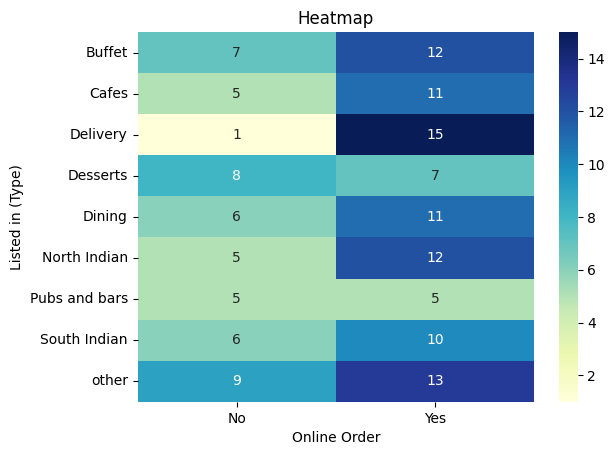

In [50]:
sns.heatmap(
    pivot_table,annot=True,cmap="YlGnBu",fmt="d")
plt.title("Heatmap")
plt.xlabel("Online Order")
plt.ylabel("Listed in (Type)")
plt.show()